In [125]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from jaxopt import AndersonAcceleration
import pickle
import os
import optax
from scipy import stats
import pandas as pd
import seaborn as sns

# Set random seed for reproducibility
key = jax.random.PRNGKey(42)
np.random.seed(42)

# Plotting style
plt.rcParams.update({'font.size': 12, 'figure.figsize': (10, 6)})

# Model parameters
m = 2  # Number of mitral neurons (glomeruli)
x = jnp.ones(m)  # Input odour signal

In [12]:
# Naka-Rushton function
def nr(x, n=4):
    """Naka-Rushton activation function"""
    return x**n / (x**n + 1)

# Unpack parameters
def unpack_theta(theta, m):
    idx = 0
    w_osn_r = theta[idx:idx+m]; idx += m
    w_osn_b = theta[idx:idx+m]; idx += m
    w_osn_g = theta[idx:idx+m]; idx += m
    w_osn_y = theta[idx:idx+m]; idx += m
    w_b_r = theta[idx:idx+m]; idx += m
    w_b_g = theta[idx:idx+m]; idx += m
    w_b_y = theta[idx:idx+m]; idx += m
    w_r_y = theta[idx:idx+m]; idx += m
    w_r_g = theta[idx:idx+m]; idx += m
    alpha = theta[idx:idx+m]; idx += m
    W_g_r = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    W_g_y = theta[idx:idx+m*m].reshape((m, m)); idx += m*m
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y

# Fixed-point function for green neurons
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha):
    """Fixed point equation for green neurons"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input)
    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input)
    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input)
    return g_new

# Solve fixed point via Anderson Acceleration
def solve_fixed_point(theta, x, m):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    g0 = jnp.zeros(m)
    aa = AndersonAcceleration(mitral_fixed_point, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
    return solution.params

# Compute mitral output
def mitral_output(theta, x, m):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    g = solve_fixed_point(theta, x, m)
    b = nr(w_osn_b * alpha * x)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r)
    return r, g, b, y


In [13]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_1000_samples_n_4_target_0.5.pkl'
with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count for summary
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

Loaded theta_opt with shape: (1000, 28)
Number of samples: 1000
Number of parameters per sample: 28


In [57]:
def check_single_theta_np(theta, x, m):
    """Check single theta sample - using numpy for compatibility"""
    r, g, b, y = mitral_output(theta, x, m)
    # Convert to numpy arrays
    r = np.array(r)
    g = np.array(g)
    b = np.array(b)
    y = np.array(y)
    
    # Check if all elements are in [0.4, 0.6]
    r_ok = (r >= 0.4).all() and (r <= 0.6).all()
    g_ok = (g >= 0.4).all() and (g <= 0.6).all()
    b_ok = (b >= 0.4).all() and (b <= 0.6).all()
    y_ok = (y >= 0.4).all() and (y <= 0.6).all()
    
    return r_ok and g_ok and b_ok and y_ok

# Process samples
n_samples = theta_opt.shape[0]
valid_mask = np.zeros(n_samples, dtype=bool)

for i in range(n_samples):
    theta_star = jnp.array(theta_opt[i, :])
    valid_mask[i] = check_single_theta_np(theta_star, x, m)
    
    if (i + 1) % 100 == 0:
        print(f"Processed {i+1}/{n_samples} samples...")

theta_opt = theta_opt[valid_mask]

print(f"Number of valid theta_opt: {theta_opt.shape[0]} out of {n_samples}")

Processed 100/1000 samples...
Processed 200/1000 samples...
Processed 300/1000 samples...
Processed 400/1000 samples...
Processed 500/1000 samples...
Processed 600/1000 samples...
Processed 700/1000 samples...
Processed 800/1000 samples...
Processed 900/1000 samples...
Processed 1000/1000 samples...
Number of valid theta_opt: 982 out of 1000


## Parameter changes preserving output


Processing 982 samples...
  Sample 1/982...
  Sample 101/982...
  Sample 201/982...
  Sample 301/982...
  Sample 401/982...
  Sample 501/982...
  Sample 601/982...
  Sample 701/982...
  Sample 801/982...
  Sample 901/982...
Completed processing 982 samples


/var/folders/h5/73c9pc297sl_8swmt3d3h45w0000gp/T/ipykernel_65182/3901778637.py:46: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=14)


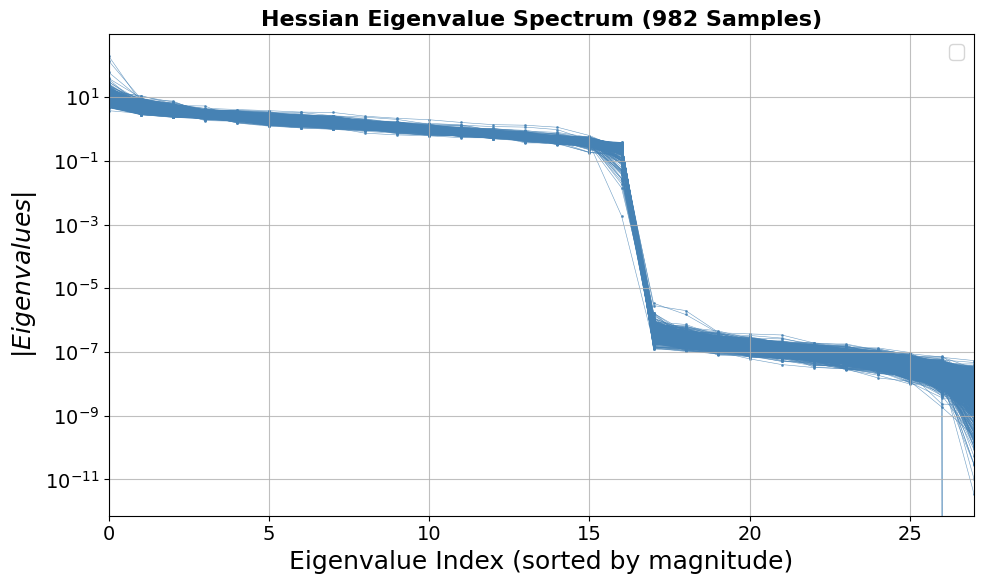

In [61]:
@jax.jit
def y_output_sum(theta):
    """Compute output y as a function of parameters"""
    r, g, b, y = mitral_output(theta, x, m)
    return jnp.sum(y)

grad = jax.jit(jax.grad(y_output_sum))
hessian = jax.jit(jax.jacrev(grad))

theta_samples = theta_opt
near_zero_threshold = 1e-9

print(f"Processing {theta_samples.shape[0]} samples...")
n_samples, n_params = theta_samples.shape[0], theta_samples.shape[1]
all_eigenvalues = np.zeros((n_samples, n_params))
all_eigenvectors = np.zeros((n_samples, n_params, n_params))

# Process all samples
for i in range(n_samples):
    if i % 100 == 0:
        print(f"  Sample {i+1}/{n_samples}...")
    
    theta_star = jnp.array(theta_samples[i, :])
    H = jnp.squeeze(hessian(theta_star))
    
    # Compute and sort eigenvalues in one step
    eigenvalues_H = np.array(jnp.linalg.eigh(H).eigenvalues)
    eigenvectors_H = np.array(jnp.linalg.eigh(H).eigenvectors)
    all_eigenvalues[i, :] = np.abs(eigenvalues_H[np.argsort(np.abs(eigenvalues_H))[::-1]])
    all_eigenvectors[i, :, :] = eigenvectors_H[:, np.argsort(np.abs(eigenvalues_H))[::-1]]

print(f"Completed processing {n_samples} samples")

# Visualise
fig, ax = plt.subplots(figsize=(10, 6))
n_params = all_eigenvalues.shape[1]

# Plot individual samples (light, transparent)
ax.semilogy(all_eigenvalues.T, 'o-', ms=1, lw=0.4, alpha=0.8, color='steelblue', zorder=1)

# Plot statistics
ax.set_xlabel('Eigenvalue Index (sorted by magnitude)', fontsize=18)
ax.set_ylabel('$|Eigenvalues|$', fontsize=18)
ax.set_xlim(0, n_params-1)
ax.tick_params(axis='both', labelsize=14, direction='out')
ax.legend(fontsize=14)
ax.grid(True, alpha=0.8)
ax.set_title(f'Hessian Eigenvalue Spectrum ({n_samples} Samples)', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()


In [137]:
# Carefully stack and melt all_eigenvectors for long-format DataFrame
n_trials, n_dims, n_ev = all_eigenvectors.shape

# Create a DataFrame in long/melted format: each (trial, eigenvector_index, dimension) gets one row
df = (
    pd.DataFrame(
        all_eigenvectors.reshape(-1, n_ev),
        columns=[f"eig_{i}" for i in range(n_ev)]
    )
    .assign(
        trial=np.repeat(np.arange(n_trials), n_dims),
        dimension=np.tile(np.arange(n_dims), n_trials)
    )
    .melt(
        id_vars=["trial", "dimension"],
        var_name="eigenvector_index",
        value_name="value"
    )
)

# Convert string indices 'eig_#' to integers for easier filtering/plotting
df["eigenvector_index"] = df["eigenvector_index"].str.extract(r"(\d+)").astype(int)

# Now, check assertion for correct extraction
assert np.allclose(
    all_eigenvectors[0, :, 0],
    df[(df['trial'] == 0) & (df['eigenvector_index'] == 0)]
    .sort_values("dimension")["value"].values
)


In [140]:
all_eigenvectors[0, :, -1]

array([ 0.00000000e+00,  4.40517701e-02,  1.01945858e-07,  1.38534503e-07,
       -1.35824278e-01, -1.47190854e-01, -8.92611519e-02, -4.56629246e-02,
        1.57618791e-01, -2.88459044e-02, -6.06970638e-02,  2.77175549e-02,
       -4.09460925e-02,  1.63741149e-02,  1.19659714e-01,  5.81634715e-02,
        1.82080179e-01,  2.95259356e-01, -1.96906257e-07, -9.89433744e-08,
        4.95822310e-01, -6.53441191e-01,  2.66676545e-01, -1.57759830e-01,
       -2.55219955e-02,  2.65792795e-02, -7.87030160e-02,  3.74931470e-02])

In [141]:
df[(df['trial']==0)&(df['eigenvector_index']==27)]

,trial,dimension,eigenvector_index,value
742392,0,0,27,0.000000e+00
742393,0,1,27,4.405177e-02
742394,0,2,27,1.019459e-07
742395,0,3,27,1.385345e-07
742396,0,4,27,-1.358243e-01
742397,0,5,27,-1.471909e-01
742398,0,6,27,-8.926115e-02
742399,0,7,27,-4.566292e-02
742400,0,8,27,1.576188e-01
742401,0,9,27,-2.884590e-02


In [ ]:
all_

<Axes: xlabel='dimension', ylabel='value'>

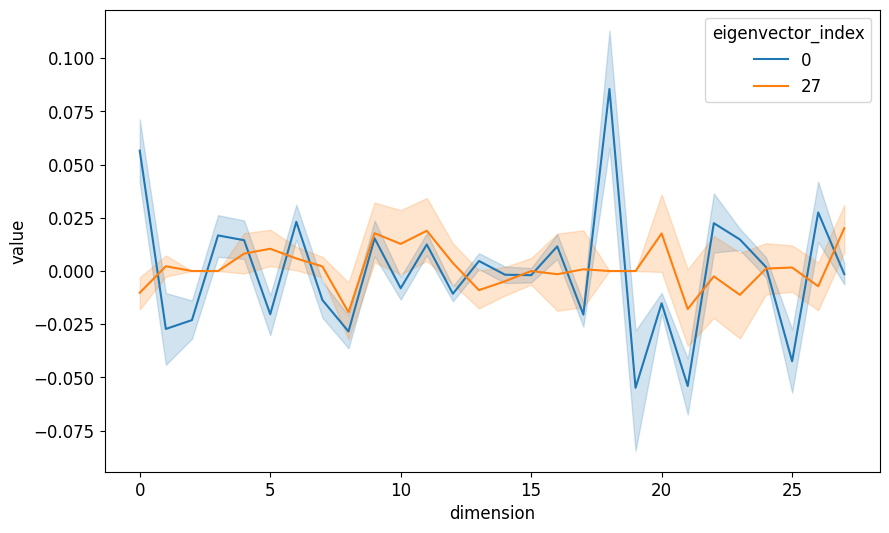

In [151]:
sns.lineplot(
    data=df[(df['eigenvector_index']==0)|(df['eigenvector_index']==27)], 
    x='dimension', 
    y='value', 
    hue='eigenvector_index',
    palette='tab10',
    # errorbar='sd'
    )

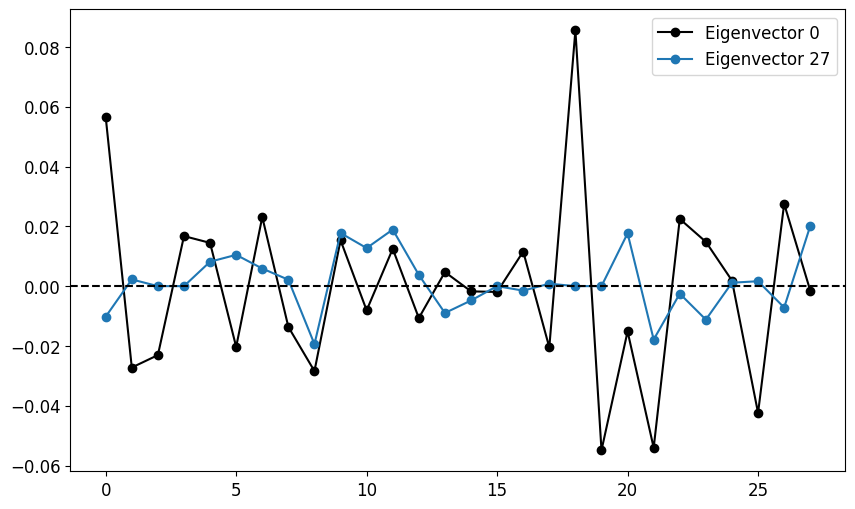

In [147]:
mean = np.mean(all_eigenvectors, axis=0)
std = np.std(all_eigenvectors, axis=0)

plt.plot(mean[:,0],'o-', c='k',label='Eigenvector 0')
plt.plot(mean[:,-1],'o-',label='Eigenvector 27')

plt.legend()
plt.axhline(y=0, color='k', linestyle='--')
plt.show()

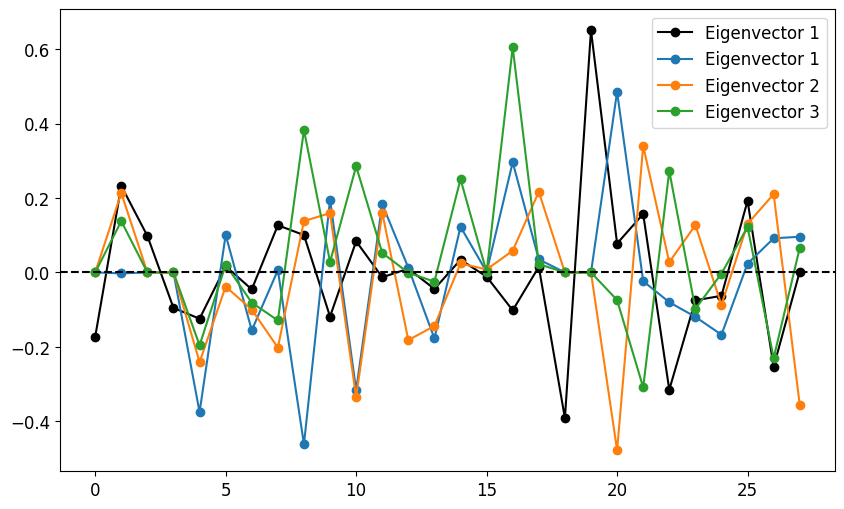

In [119]:

i=50
#plot the eigenvector
plt.plot(all_eigenvectors[i][:,0],'o-', c='k',label='Eigenvector 1')
plt.plot(all_eigenvectors[i][:,-1],'o-',label='Eigenvector 1')
plt.plot(all_eigenvectors[i][:,-2],'o-',label='Eigenvector 2')
plt.plot(all_eigenvectors[i][:,-3],'o-',label='Eigenvector 3')
plt.legend()
plt.axhline(y=0, color='k', linestyle='--')
plt.show()



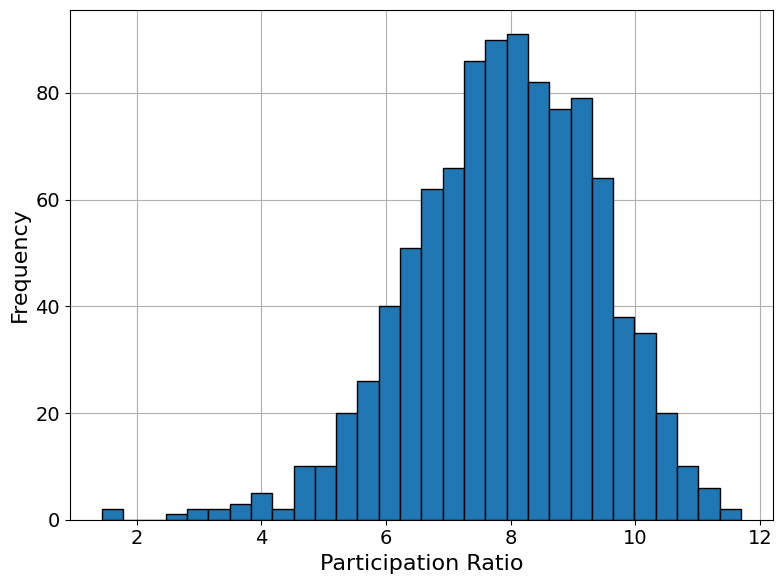

In [59]:
## participation ratio
## plot histogram of participation ratio

participation_ratios = []
for i in range(theta_opt.shape[0]):
    H = hessian(theta_opt[i, :])
    H = jnp.squeeze(H)
    eigenvalues_H = jnp.linalg.eigh(H)[0]
    ppr = (jnp.sum(jnp.abs(eigenvalues_H)) ** 2) / jnp.sum(eigenvalues_H ** 2)
    participation_ratios.append(ppr)

participation_ratios = np.array(participation_ratios)

plt.figure(figsize=(8, 6))
plt.grid(True, zorder=0)
plt.hist(participation_ratios, bins=30, edgecolor='black', zorder=2)
plt.xlabel('Participation Ratio', fontsize=16)
plt.ylabel('Frequency', fontsize=16)
plt.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.savefig('Figures/participation_ratio.eps')
plt.show()

In [83]:
theta_picked = theta_opt[0]
e_vector_1 = all_eigenvectors[0][:, 0]
e_vector_2 = all_eigenvectors[0][:, 8]
e_vector_3 = all_eigenvectors[0][:, 14]
e_vector_4 = all_eigenvectors[0][:, 18]
e_vector_5 = all_eigenvectors[0][:, 27]

#normalise the eigenvectors
de_magnitude = 0.01*jnp.linalg.norm(theta_picked)
print(de_magnitude)
e_vector_1 = e_vector_1 / jnp.linalg.norm(e_vector_1) * de_magnitude
e_vector_2 = e_vector_2 / jnp.linalg.norm(e_vector_2) * de_magnitude
e_vector_3 = e_vector_3 / jnp.linalg.norm(e_vector_3) * de_magnitude
e_vector_4 = e_vector_4 / jnp.linalg.norm(e_vector_4) * de_magnitude
e_vector_5 = e_vector_5 / jnp.linalg.norm(e_vector_5) * de_magnitude

r_0, g_0, b_0, y_0 = mitral_output(theta_picked, x, m)
r_1, g_1, b_1, y_1 = mitral_output(theta_picked + e_vector_1, x, m)
r_2, g_2, b_2, y_2 = mitral_output(theta_picked + e_vector_2, x, m)
r_3, g_3, b_3, y_3 = mitral_output(theta_picked + e_vector_3, x, m)
r_4, g_4, b_4, y_4 = mitral_output(theta_picked + e_vector_4, x, m)
r_5, g_5, b_5, y_5 = mitral_output(theta_picked + e_vector_5, x, m)

import pandas as pd

# Convert to numpy arrays if not already
r_0, g_0, b_0, y_0 = np.array(r_0), np.array(g_0), np.array(b_0), np.array(y_0)
r_1, g_1, b_1, y_1 = np.array(r_1), np.array(g_1), np.array(b_1), np.array(y_1)
r_2, g_2, b_2, y_2 = np.array(r_2), np.array(g_2), np.array(b_2), np.array(y_2)
r_3, g_3, b_3, y_3 = np.array(r_3), np.array(g_3), np.array(b_3), np.array(y_3)
r_4, g_4, b_4, y_4 = np.array(r_4), np.array(g_4), np.array(b_4), np.array(y_4)
r_5, g_5, b_5, y_5 = np.array(r_5), np.array(g_5), np.array(b_5), np.array(y_5)

# Create a dictionary for the dataframe
data = {
    "Original": [r_0, g_0, b_0, y_0],
    "Eigenvec 1": [r_1, g_1, b_1, y_1],
    "Eigenvec 2": [r_2, g_2, b_2, y_2],
    "Eigenvec 3": [r_3, g_3, b_3, y_3],
    "Eigenvec 4": [r_4, g_4, b_4, y_4],
    "Eigenvec 5": [r_5, g_5, b_5, y_5],
}

channels = ["r", "g", "b", "y"]
df = pd.DataFrame(data, index=channels)

print("="*60)
print("Output Values Comparison (as pandas DataFrame)")
print("="*60)
print(df)
print("="*60)


0.036905743
Output Values Comparison (as pandas DataFrame)
                  Original                Eigenvec 1  \
r  [0.49999994, 0.5000001]   [0.46893412, 0.5470972]   
g   [0.5000001, 0.5000001]   [0.45860484, 0.5555982]   
b  [0.5000001, 0.49999994]  [0.48096654, 0.51665384]   
y               [0.5, 0.5]   [0.45341438, 0.5758466]   

                 Eigenvec 2                Eigenvec 3  \
r  [0.49302977, 0.49973953]  [0.49987262, 0.49956268]   
g  [0.50780004, 0.50102377]   [0.5013382, 0.50132036]   
b   [0.5281039, 0.49631846]  [0.50031483, 0.50533813]   
y   [0.5111272, 0.49946475]    [0.5007955, 0.5011713]   

                Eigenvec 4               Eigenvec 5  
r               [0.5, 0.5]               [0.5, 0.5]  
g         [0.5000001, 0.5]         [0.5000001, 0.5]  
b  [0.5000001, 0.49999994]  [0.5000001, 0.49999994]  
y  [0.5000001, 0.49999988]        [0.5, 0.49999994]  


In [84]:
df

,Original,Eigenvec 1,Eigenvec 2,Eigenvec 3,Eigenvec 4,Eigenvec 5
r,"[0.49999994, 0.5000001]","[0.46893412, 0.5470972]","[0.49302977, 0.49973953]","[0.49987262, 0.49956268]","[0.5, 0.5]","[0.5, 0.5]"
g,"[0.5000001, 0.5000001]","[0.45860484, 0.5555982]","[0.50780004, 0.50102377]","[0.5013382, 0.50132036]","[0.5000001, 0.5]","[0.5000001, 0.5]"
b,"[0.5000001, 0.49999994]","[0.48096654, 0.51665384]","[0.5281039, 0.49631846]","[0.50031483, 0.50533813]","[0.5000001, 0.49999994]","[0.5000001, 0.49999994]"
y,"[0.5, 0.5]","[0.45341438, 0.5758466]","[0.5111272, 0.49946475]","[0.5007955, 0.5011713]","[0.5000001, 0.49999988]","[0.5, 0.49999994]"


In [94]:
de_magnitude = 0.01*jnp.linalg.norm(theta_picked)
print(de_magnitude)

0.036905743


In [104]:
y_0 = df.iloc[3,0]
norm_y_0 = jnp.linalg.norm(theta_picked)
a = (df.iloc[3,1]-y_0)/y_0
print(a)
print(de_magnitude)
print(a/de_magnitude)

[-0.09317124  0.15169322]
0.036905743
[-2.5245728  4.1102877]


In [ ]:
#add a new row to the dataframe

y_0 = df.iloc[3,0]
norm_y_0 = jnp.linalg.norm(theta_picked)
a = ((df.iloc[3,1]-y_0)/y_0) / de_magnitude
b = ((df.iloc[3,2]-y_0)/y_0) / de_magnitude
c = ((df.iloc[3,3]-y_0)/y_0) / de_magnitude
d = ((df.iloc[3,4]-y_0)/y_0) / de_magnitude
e = ((df.iloc[3,5]-y_0)/y_0) / de_magnitude


df.loc['Percentage change'] = [0,a,b,c,d,e]
df

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (6,) + inhomogeneous part.

In [88]:
df.iloc[1,3]

array([0.5013382 , 0.50132036], dtype=float32)

In [87]:

y_0_val = y_0  # original
theta_0_val = theta_picked

results = {}
for i in range(1, 6):
    y_new = eval(f'y_{i}')
    theta_new = theta_picked + eval(f'e_vector_{i}')
    # Compute relative change in y (elementwise)
    numerator = (y_new - y_0_val) / y_0_val
    denominator = (theta_new - theta_0_val) / theta_0_val

    # For denominator, if theta_picked is zero anywhere, avoid division by zero
    denominator = np.where(theta_0_val != 0, denominator, np.nan)

    # Now, the full ratio
    ratio = numerator / denominator  # this is a 2-d array

    results[f"Eigenvec {i}"] = ratio

# Organize into DataFrame for clarity
ratios_df = pd.DataFrame(
    {
        key: [v[0], v[1]] if v.shape == (2,) else v.tolist()  # support flat or (2,)
        for key, v in results.items()
    },
    index=["y[0]", "y[1]"]
)

print("===============================================")
print("Changes in percentage")
print("===============================================")
print(ratios_df)
print("===============================================")

ratios_df


ValueError: operands could not be broadcast together with shapes (2,) (28,) 

dot products